In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

bronze = spark.table("workspace.bronze.elexon_system_prices")

latest_first = Window.partitionBy("settlementDate", "settlementPeriod").orderBy(
    F.col("createdDateTime").desc(), F.col("_fetched_at").desc())

silver = (
    bronze
    .withColumn("_rank", F.row_number().over(latest_first))
    .filter("_rank = 1")
    .select(
        F.to_date("settlementDate").alias("settlement_date"),
        F.col("settlementPeriod").cast("int").alias("settlement_period"),
        F.to_timestamp("startTime").alias("start_time_utc"),
        F.col("systemSellPrice").alias("system_sell_price"),
        F.col("systemBuyPrice").alias("system_buy_price"),
        F.col("netImbalanceVolume").alias("net_imbalance_volume"),
        F.col("priceDerivationCode").alias("price_derivation_code"),
        F.to_timestamp("createdDateTime").alias("published_at_utc"),
        "_fetched_at", "_source_file",
    )
)

(silver.write.format("delta").mode("overwrite").option("overwriteSchema", True)
       .saveAsTable("workspace.silver.system_prices"))

display(spark.sql("""
    SELECT COUNT(*)                                                 AS rows,
           COUNT(DISTINCT settlement_date, settlement_period)       AS unique_half_hours,
           SUM(CASE WHEN system_sell_price IS NULL THEN 1 ELSE 0 END) AS null_prices,
           SUM(CASE WHEN system_sell_price <> system_buy_price THEN 1 ELSE 0 END) AS sell_ne_buy,
           MIN(system_sell_price)                                   AS min_price,
           MAX(system_sell_price)                                   AS max_price,
           MIN(start_time_utc)                                      AS first_half_hour,
           MAX(start_time_utc)                                      AS last_half_hour
    FROM workspace.silver.system_prices
"""))

rows,unique_half_hours,null_prices,sell_ne_buy,min_price,max_price,first_half_hour,last_half_hour
35663,35663,0,0,-97.92,2900.0,2024-09-30T23:00:00.000Z,2026-10-13T22:00:00.000Z


In [0]:
sp = spark.table("workspace.silver.system_prices")

print("Highest 10:")
display(sp.orderBy(F.col("system_sell_price").desc())
          .select("settlement_date", "settlement_period", "start_time_utc",
                  "system_sell_price", "net_imbalance_volume", "price_derivation_code")
          .limit(10))

print("Lowest 10:")
display(sp.orderBy("system_sell_price")
          .select("settlement_date", "settlement_period", "start_time_utc",
                  "system_sell_price", "net_imbalance_volume", "price_derivation_code")
          .limit(10))

display(sp.select(
    F.expr("percentile(system_sell_price, array(0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99))")
     .alias("p1_p5_p25_median_p75_p95_p99"),
    F.round(F.avg("system_sell_price"), 2).alias("mean"),
    F.sum(F.when(F.col("system_sell_price") < 0, 1).otherwise(0)).alias("negative_half_hours"),
    F.sum(F.when(F.col("system_sell_price") > 500, 1).otherwise(0)).alias("above_500"),
))

Highest 10:


settlement_date,settlement_period,start_time_utc,system_sell_price,net_imbalance_volume,price_derivation_code
2025-01-08,37,2025-01-08T18:00:00.000Z,2900.0,402.715491729798,P
2025-01-08,36,2025-01-08T17:30:00.000Z,2900.0,337.82472222222225,P
2025-01-08,35,2025-01-08T17:00:00.000Z,2900.0,338.23,P
2025-01-08,38,2025-01-08T18:30:00.000Z,2900.0,356.3919696969697,P
2025-01-08,34,2025-01-08T16:30:00.000Z,2900.0,508.9452619047619,P
2025-01-08,33,2025-01-08T16:00:00.000Z,2900.0,552.062702020202,P
2025-01-08,32,2025-01-08T15:30:00.000Z,2900.0,284.4552064033189,P
2025-01-08,31,2025-01-08T15:00:00.000Z,2900.0,159.88493166666666,P
2025-01-08,27,2025-01-08T13:00:00.000Z,1950.0,29.17430709093785,P
2025-01-08,26,2025-01-08T12:30:00.000Z,1950.0,111.91191018461008,P


Lowest 10:


settlement_date,settlement_period,start_time_utc,system_sell_price,net_imbalance_volume,price_derivation_code
2026-04-06,30,2026-04-06T13:30:00.000Z,-97.92,-1665.9512491699527,N
2025-03-30,29,2025-03-30T14:00:00.000Z,-95.0,-1288.9834322589552,N
2026-04-06,29,2026-04-06T13:00:00.000Z,-90.0,-1508.6878161656775,N
2025-04-05,26,2025-04-05T11:30:00.000Z,-87.32,-856.0398720833333,N
2025-09-06,27,2025-09-06T12:00:00.000Z,-87.0,-1802.3472614191526,N
2025-09-06,28,2025-09-06T12:30:00.000Z,-86.99629330841908,-1977.322019612596,N
2026-06-28,29,2026-06-28T13:00:00.000Z,-85.66,-1669.510592638889,N
2026-06-28,30,2026-06-28T13:30:00.000Z,-85.66,-1963.1528557125139,N
2026-09-05,28,2026-09-05T12:30:00.000Z,-84.88,-1428.1759895120617,N
2026-04-21,30,2026-04-21T13:30:00.000Z,-83.99,-1234.2681969278049,N


p1_p5_p25_median_p75_p95_p99,mean,negative_half_hours,above_500
"List(-25.0, -1.649980392156853, 64.9, 91.5, 118.0, 164.9, 215.99404799999996)",90.45,1950,29


In [0]:
import re

def to_snake(name: str) -> str:
    """systemSellPrice -> system_sell_price"""
    return re.sub(r"(?<!^)(?=[A-Z])", "_", name).lower()


def build_silver(bronze_table: str, silver_table: str, key_fields: list[str]) -> None:
    """One row per (settlement date, period, *key_fields), keeping the latest version."""
    df = spark.table(f"workspace.bronze.{bronze_table}")

    newest_first = ([F.col("publishTime").desc()] if "publishTime" in df.columns else []) \
                   + [F.col("_fetched_at").desc()]
    w = Window.partitionBy("settlementDate", "settlementPeriod", *key_fields).orderBy(*newest_first)
    df = df.withColumn("_rank", F.row_number().over(w)).filter("_rank = 1")

    cols = []
    for c in df.columns:
        if c in ("_rank", "_ingested_at", "_partition_day"):
            continue
        elif c == "settlementDate":
            cols.append(F.to_date(c).alias("settlement_date"))
        elif c == "settlementPeriod":
            cols.append(F.col(c).cast("int").alias("settlement_period"))
        elif c == "startTime":
            cols.append(F.to_timestamp(c).alias("start_time_utc"))
        elif c == "publishTime":
            cols.append(F.to_timestamp(c).alias("published_at_utc"))
        elif c.startswith("_"):
            cols.append(F.col(c))
        else:
            cols.append(F.col(c).alias(to_snake(c)))

    (df.select(*cols).write.format("delta").mode("overwrite")
       .option("overwriteSchema", True).saveAsTable(f"workspace.silver.{silver_table}"))


def check_silver(bronze_table: str, silver_table: str, key_fields: list[str]):
    s = spark.table(f"workspace.silver.{silver_table}")
    keys = ["settlement_date", "settlement_period"] + [to_snake(k) for k in key_fields]
    # Half hours a UK day really has: 48, or 46 / 50 on clock change days
    expected = ((F.unix_timestamp(F.to_utc_timestamp(F.date_add("settlement_date", 1), "Europe/London"))
                 - F.unix_timestamp(F.to_utc_timestamp(F.col("settlement_date").cast("timestamp"),
                                                       "Europe/London"))) / 1800).cast("int")
    per_day = (s.groupBy("settlement_date")
                .agg(F.countDistinct("settlement_period").alias("periods"))
                .withColumn("expected", expected))
    return (silver_table,
            spark.table(f"workspace.bronze.{bronze_table}").count(),
            s.count(),
            s.select(*keys).distinct().count(),
            per_day.count(),
            per_day.filter("periods <> expected").count())


TABLES = [  # (bronze table, silver table, fields that identify a row within a half hour)
    ("elexon_demand_outturn", "demand_outturn", []),
    ("elexon_generation_by_fuel", "generation_by_fuel", ["fuelType"]),
    ("elexon_wind_solar_actual", "wind_solar_actual", ["psrType"]),
]

results = []
for bronze_table, silver_table, keys in TABLES:
    build_silver(bronze_table, silver_table, keys)
    results.append(check_silver(bronze_table, silver_table, keys))
    print("done:", silver_table)

display(spark.createDataFrame(results,
        "table string, bronze_rows long, silver_rows long, unique_keys long, "
        "days long, incomplete_days long"))

done: demand_outturn
done: generation_by_fuel
done: wind_solar_actual


table,bronze_rows,silver_rows,unique_keys,days,incomplete_days
demand_outturn,35664,35664,35664,743,0
generation_by_fuel,713280,713280,713280,743,0
wind_solar_actual,108963,104652,104652,743,60


In [0]:
from pyspark.sql import functions as F
b = spark.table("workspace.bronze.elexon_wind_solar_actual")
s = spark.table("workspace.silver.wind_solar_actual")

expected = ((F.unix_timestamp(F.to_utc_timestamp(F.date_add("settlement_date", 1), "Europe/London"))
             - F.unix_timestamp(F.to_utc_timestamp(F.col("settlement_date").cast("timestamp"),
                                                   "Europe/London"))) / 1800).cast("int")

bronze_per_day = (b.groupBy(F.to_date("settlementDate").alias("settlement_date"))
                   .agg(F.count("*").alias("bronze_rows"),
                        F.countDistinct("publishTime").alias("publish_times")))
silver_per_day = (s.groupBy("settlement_date")
                   .agg(F.countDistinct("settlement_period").alias("periods_present"),
                        F.count("*").alias("silver_rows"))
                   .withColumn("periods_expected", expected))

days = (silver_per_day.join(bronze_per_day, "settlement_date")
        .withColumn("periods_missing", F.col("periods_expected") - F.col("periods_present"))
        .filter("periods_missing > 0")
        .orderBy("settlement_date"))

print("incomplete days:", days.count(),
      "| total periods missing:", days.agg(F.sum("periods_missing")).first()[0])
display(days)

incomplete days: 60 | total periods missing: 780


settlement_date,periods_present,silver_rows,periods_expected,bronze_rows,publish_times,periods_missing
2024-10-06,47,141,48,141,47,1
2024-11-02,47,141,48,141,47,1
2024-12-04,38,114,48,114,38,10
2024-12-26,47,141,48,141,47,1
2025-03-01,47,141,48,141,47,1
2025-04-03,47,141,48,141,47,1
2025-04-05,44,132,48,132,44,4
2025-04-06,45,135,48,135,45,3
2025-04-28,47,141,48,141,47,1
2025-04-29,47,141,48,141,47,1


In [0]:
from pyspark.sql import functions as F

fuel_wind = (spark.table("workspace.silver.generation_by_fuel")
             .filter("fuel_type = 'WIND'")
             .select("settlement_date", "settlement_period",
                     F.col("generation").alias("fuel_wind_mw")))

ws_wind = (spark.table("workspace.silver.wind_solar_actual")
           .filter("psr_type IN ('Wind Onshore', 'Wind Offshore')")
           .groupBy("settlement_date", "settlement_period")
           .agg(F.count("*").alias("parts"), F.sum("quantity").alias("ws_wind_mw"))
           .filter("parts = 2"))  # only half hours where both onshore and offshore exist

both = fuel_wind.join(ws_wind, ["settlement_date", "settlement_period"])

display(both.select(
    F.count("*").alias("half_hours_compared"),
    F.sum(F.when(F.col("fuel_wind_mw") == 0, 1).otherwise(0)).alias("fuel_wind_zero"),
    F.round(F.corr("fuel_wind_mw", "ws_wind_mw"), 4).alias("correlation"),
    F.round(F.avg("fuel_wind_mw"), 0).alias("avg_fuel_wind_mw"),
    F.round(F.avg("ws_wind_mw"), 0).alias("avg_ws_wind_mw"),
    F.round(F.avg(F.col("ws_wind_mw") - F.col("fuel_wind_mw")), 0).alias("avg_difference_mw"),
    F.round(F.expr("avg(try_divide(ws_wind_mw, fuel_wind_mw))"), 3).alias("avg_ratio"),
))

half_hours_compared,fuel_wind_zero,correlation,avg_fuel_wind_mw,avg_ws_wind_mw,avg_difference_mw,avg_ratio
34884,8,0.9437,8108.0,9317.0,1209.0,1.154


In [0]:
from pyspark.sql import functions as F

fuel_wind = (spark.table("workspace.silver.generation_by_fuel")
             .filter("fuel_type = 'WIND'")
             .select("settlement_date", "settlement_period",
                     F.col("generation").alias("fuel_wind")))

ws = (spark.table("workspace.silver.wind_solar_actual")
      .groupBy("settlement_date", "settlement_period")
      .pivot("psr_type", ["Wind Onshore", "Wind Offshore"])
      .agg(F.first("quantity"))
      .withColumnRenamed("Wind Onshore", "onshore")
      .withColumnRenamed("Wind Offshore", "offshore")
      .dropna(subset=["onshore", "offshore"]))

d = (fuel_wind.join(ws, ["settlement_date", "settlement_period"])
     .filter("fuel_wind > 0")
     .withColumn("diff", F.col("onshore") + F.col("offshore") - F.col("fuel_wind")))

display(d.select(
    F.count("*").alias("half_hours"),
    F.round(100 * F.avg(F.when(F.col("diff") < 0, 1).otherwise(0)), 1).alias("pct_diff_negative"),
    F.expr("transform(percentile(diff, array(0.05, 0.5, 0.95)), x -> round(x, 0))")
     .alias("diff_p5_median_p95"),
    F.round(F.corr("diff", "onshore"), 3).alias("corr_diff_vs_onshore"),
    F.round(F.corr("diff", "offshore"), 3).alias("corr_diff_vs_offshore"),
    F.round(F.corr("offshore", "fuel_wind"), 3).alias("corr_offshore_vs_fuel"),
    F.round(F.avg("onshore"), 0).alias("avg_onshore"),
    F.round(F.avg("offshore"), 0).alias("avg_offshore"),
    F.round(F.avg("fuel_wind"), 0).alias("avg_fuel_wind"),
))

half_hours,pct_diff_negative,diff_p5_median_p95,corr_diff_vs_onshore,corr_diff_vs_offshore,corr_offshore_vs_fuel,avg_onshore,avg_offshore,avg_fuel_wind
34876,8.2,"List(-2691.0, 1222.0, 3976.0)",0.604,0.677,0.893,3890.0,5428.0,8110.0


In [0]:
from pyspark.sql import functions as F

fuel = (spark.table("workspace.silver.generation_by_fuel")
        .filter("fuel_type = 'WIND' AND generation > 0")
        .select("start_time_utc", F.col("generation").alias("fuel_wind")))

ws = (spark.table("workspace.silver.wind_solar_actual")
      .filter("psr_type IN ('Wind Onshore', 'Wind Offshore')")
      .groupBy("start_time_utc")
      .agg(F.count("*").alias("parts"), F.sum("quantity").alias("ws_wind"))
      .filter("parts = 2")
      .select("start_time_utc", "ws_wind"))

results = []
for k in range(-4, 5):  # shift the wind and solar data by k half hours
    shifted = ws.withColumn("start_time_utc",
                            F.col("start_time_utc") + F.expr(f"INTERVAL {30 * k} MINUTES"))
    j = fuel.join(shifted, "start_time_utc")
    r = j.select(F.corr("fuel_wind", "ws_wind").alias("corr"),
                 F.avg(F.abs(F.col("ws_wind") - F.col("fuel_wind"))).alias("mean_abs_gap"),
                 F.avg(F.when(F.col("ws_wind") < F.col("fuel_wind"), 1).otherwise(0))
                  .alias("share_negative")).first()
    results.append((k, round(r["corr"], 4), round(r["mean_abs_gap"]),
                    round(100 * r["share_negative"], 1)))

display(spark.createDataFrame(results,
        "shift_half_hours int, correlation double, mean_abs_gap_mw long, pct_negative double"))

shift_half_hours,correlation,mean_abs_gap_mw,pct_negative
-4,0.9251,1944,17.0
-3,0.9323,1896,14.2
-2,0.938,1863,11.3
-1,0.9423,1846,9.2
0,0.9442,1842,8.2
1,0.9427,1846,9.0
2,0.939,1863,11.2
3,0.9337,1897,14.0
4,0.9271,1947,16.9


In [0]:
from pyspark.sql import functions as F

wf = spark.table("workspace.bronze.elexon_wind_forecast")
print(wf.columns)  # so we can see the field names if anything goes wrong

fc = (wf.select(F.to_timestamp("startTime").alias("start_time_utc"),
                F.to_timestamp("publishTime").alias("published"),
                F.col("generation").alias("forecast_mw"))
        .withColumn("hours_ahead",
                    (F.unix_timestamp("start_time_utc") - F.unix_timestamp("published")) / 3600)
        .filter("hours_ahead BETWEEN 1 AND 6")
        .groupBy("start_time_utc").agg(F.avg("forecast_mw").alias("forecast_mw")))

fuel = (spark.table("workspace.silver.generation_by_fuel")
        .filter("fuel_type = 'WIND'")
        .select("start_time_utc", F.col("generation").alias("fuel_wind")))

ws = (spark.table("workspace.silver.wind_solar_actual")
      .filter("psr_type IN ('Wind Onshore', 'Wind Offshore')")
      .groupBy("start_time_utc")
      .agg(F.count("*").alias("parts"), F.sum("quantity").alias("ws_wind"))
      .filter("parts = 2"))

j = fc.join(fuel, "start_time_utc").join(ws, "start_time_utc")

display(j.select(
    F.count("*").alias("hours_compared"),
    F.round(F.avg("forecast_mw"), 0).alias("avg_forecast"),
    F.round(F.avg(F.col("forecast_mw") - F.col("fuel_wind")), 0).alias("bias_vs_fuel"),
    F.round(F.avg(F.col("forecast_mw") - F.col("ws_wind")), 0).alias("bias_vs_ws"),
    F.round(F.avg(F.abs(F.col("forecast_mw") - F.col("fuel_wind"))), 0).alias("mae_vs_fuel"),
    F.round(F.avg(F.abs(F.col("forecast_mw") - F.col("ws_wind"))), 0).alias("mae_vs_ws"),
    F.round(F.corr("forecast_mw", "fuel_wind"), 4).alias("corr_vs_fuel"),
    F.round(F.corr("forecast_mw", "ws_wind"), 4).alias("corr_vs_ws"),
))

['generation', 'publishTime', 'settlementDate', 'settlementPeriod', 'startTime', '_source_file', '_partition_day', '_fetched_at', '_ingested_at']


hours_compared,avg_forecast,bias_vs_fuel,bias_vs_ws,mae_vs_fuel,mae_vs_ws,corr_vs_fuel,corr_vs_ws
3566,9068.0,1071.0,-392.0,1329.0,1296.0,0.9661,0.9447


In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

UK = "Europe/London"
b = spark.table("workspace.bronze.carbon_intensity")

start = F.to_timestamp("from", "yyyy-MM-dd'T'HH:mmX")
local_date = F.to_date(F.from_utc_timestamp(start, UK))
day_start_utc = F.to_utc_timestamp(local_date.cast("timestamp"), UK)

ci = (b
      .withColumn("start_time_utc", start)
      .withColumn("settlement_date", local_date)
      .withColumn("settlement_period",
                  ((F.unix_timestamp(start) - F.unix_timestamp(day_start_utc)) / 1800 + 1).cast("int"))
      .filter(F.col("settlement_date") == F.col("_partition_day"))  # drop the extra window
      .withColumn("_rank", F.row_number().over(
          Window.partitionBy("start_time_utc").orderBy(F.col("_fetched_at").desc())))
      .filter("_rank = 1")
      .select("settlement_date", "settlement_period", "start_time_utc",
              F.to_timestamp("to", "yyyy-MM-dd'T'HH:mmX").alias("end_time_utc"),
              F.col("intensity.forecast").alias("intensity_forecast"),
              F.col("intensity.actual").alias("intensity_actual"),
              F.col("intensity.index").alias("intensity_index"),
              "_fetched_at", "_source_file"))

(ci.write.format("delta").mode("overwrite").option("overwriteSchema", True)
   .saveAsTable("workspace.silver.carbon_intensity"))

s = spark.table("workspace.silver.carbon_intensity")
sp = spark.table("workspace.silver.system_prices").select(
    "start_time_utc", F.col("settlement_date").alias("elexon_date"),
    F.col("settlement_period").alias("elexon_period"))
x = s.join(sp, "start_time_utc")

display(s.select(
    F.count("*").alias("rows"),
    F.countDistinct("start_time_utc").alias("unique_half_hours"),
    F.sum(F.when(F.col("intensity_actual").isNull(), 1).otherwise(0)).alias("null_actual"),
    F.sum(F.when(F.col("intensity_forecast").isNull(), 1).otherwise(0)).alias("null_forecast"),
    F.min("intensity_actual").alias("min_actual"),
    F.max("intensity_actual").alias("max_actual"),
    F.round(F.avg("intensity_actual"), 1).alias("avg_actual"),
))
display(x.select(
    F.count("*").alias("matched_with_elexon"),
    F.sum(F.when((F.col("settlement_date") != F.col("elexon_date")) |
                 (F.col("settlement_period") != F.col("elexon_period")), 1).otherwise(0))
     .alias("label_mismatches"),
))

rows,unique_half_hours,null_actual,null_forecast,min_actual,max_actual,avg_actual
35664,35664,0,43,0,303,128.4


matched_with_elexon,label_mismatches
35663,0


In [0]:
from pyspark.sql import functions as F

for t in ["elexon_demand_forecast", "elexon_wind_forecast"]:
    df = spark.table(f"workspace.bronze.{t}")
    print(t, df.columns)
    display(df.filter("_partition_day = '2025-10-26'")
              .orderBy("startTime", "publishTime").limit(5))

elexon_demand_forecast ['boundary', 'nationalDemand', 'publishTime', 'settlementDate', 'settlementPeriod', 'startTime', 'transmissionSystemDemand', '_source_file', '_partition_day', '_fetched_at', '_ingested_at']


boundary,nationalDemand,publishTime,settlementDate,settlementPeriod,startTime,transmissionSystemDemand,_source_file,_partition_day,_fetched_at,_ingested_at
N,26500,2025-10-25T08:16:00Z,2025-10-25,20,2025-10-25T08:30:00Z,28762,dbfs:/Volumes/workspace/bronze/landing/files/elexon_demand_forecast/2025-10-26/20261013T234048232401Z_e7d44127.json,2025-10-26,2026-10-13T23:40:48.232Z,2026-10-16T00:47:30.237Z
N,26043,2025-10-25T08:16:00Z,2025-10-25,21,2025-10-25T09:00:00Z,28310,dbfs:/Volumes/workspace/bronze/landing/files/elexon_demand_forecast/2025-10-26/20261013T234048232401Z_e7d44127.json,2025-10-26,2026-10-13T23:40:48.232Z,2026-10-16T00:47:30.237Z
N,26043,2025-10-25T08:46:00Z,2025-10-25,21,2025-10-25T09:00:00Z,28310,dbfs:/Volumes/workspace/bronze/landing/files/elexon_demand_forecast/2025-10-26/20261013T234047729174Z_f858943d.json,2025-10-26,2026-10-13T23:40:47.729Z,2026-10-16T00:47:30.237Z
N,25510,2025-10-25T08:16:00Z,2025-10-25,22,2025-10-25T09:30:00Z,27777,dbfs:/Volumes/workspace/bronze/landing/files/elexon_demand_forecast/2025-10-26/20261013T234048232401Z_e7d44127.json,2025-10-26,2026-10-13T23:40:48.232Z,2026-10-16T00:47:30.237Z
N,25510,2025-10-25T08:46:00Z,2025-10-25,22,2025-10-25T09:30:00Z,27777,dbfs:/Volumes/workspace/bronze/landing/files/elexon_demand_forecast/2025-10-26/20261013T234047729174Z_f858943d.json,2025-10-26,2026-10-13T23:40:47.729Z,2026-10-16T00:47:30.237Z


elexon_wind_forecast ['generation', 'publishTime', 'settlementDate', 'settlementPeriod', 'startTime', '_source_file', '_partition_day', '_fetched_at', '_ingested_at']


generation,publishTime,settlementDate,settlementPeriod,startTime,_source_file,_partition_day,_fetched_at,_ingested_at
19785,2025-10-25T08:30:00Z,2025-10-24,43,2025-10-24T20:00:00Z,dbfs:/Volumes/workspace/bronze/landing/files/elexon_wind_forecast/2025-10-26/20261013T235251040222Z_91d19656.json,2025-10-26,2026-10-13T23:52:51.040Z,2026-10-16T00:51:15.942Z
19970,2025-10-25T08:30:00Z,2025-10-24,45,2025-10-24T21:00:00Z,dbfs:/Volumes/workspace/bronze/landing/files/elexon_wind_forecast/2025-10-26/20261013T235251040222Z_91d19656.json,2025-10-26,2026-10-13T23:52:51.040Z,2026-10-16T00:51:15.942Z
20088,2025-10-25T08:30:00Z,2025-10-24,47,2025-10-24T22:00:00Z,dbfs:/Volumes/workspace/bronze/landing/files/elexon_wind_forecast/2025-10-26/20261013T235251040222Z_91d19656.json,2025-10-26,2026-10-13T23:52:51.040Z,2026-10-16T00:51:15.942Z
20125,2025-10-25T08:30:00Z,2025-10-25,1,2025-10-24T23:00:00Z,dbfs:/Volumes/workspace/bronze/landing/files/elexon_wind_forecast/2025-10-26/20261013T235251040222Z_91d19656.json,2025-10-26,2026-10-13T23:52:51.040Z,2026-10-16T00:51:15.942Z
19997,2025-10-25T08:30:00Z,2025-10-25,3,2025-10-25T00:00:00Z,dbfs:/Volumes/workspace/bronze/landing/files/elexon_wind_forecast/2025-10-26/20261013T235251040222Z_91d19656.json,2025-10-26,2026-10-13T23:52:51.040Z,2026-10-16T00:51:15.942Z


In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

UK = "Europe/London"

def decision_time_utc(target_date_col):
    """10:00 UK time on the day before the target day, as a UTC timestamp."""
    return F.to_utc_timestamp(
        F.to_timestamp(F.concat(F.date_sub(target_date_col, 1).cast("string"), F.lit(" 10:00:00"))),
        UK)

def build_asof(bronze_table, silver_table, value_cols):
    b = spark.table(f"workspace.bronze.{bronze_table}")
    df = (b
          .withColumn("settlement_date", F.to_date("settlementDate"))
          .filter(F.col("settlement_date") == F.col("_partition_day"))    # target day only
          .withColumn("published_at_utc", F.to_timestamp("publishTime"))
          .withColumn("decision_time_utc", decision_time_utc(F.col("settlement_date")))
          .filter(F.col("published_at_utc") <= F.col("decision_time_utc"))  # the 10am rule
          .withColumn("_rank", F.row_number().over(
              Window.partitionBy("settlement_date", "settlementPeriod")
                    .orderBy(F.col("published_at_utc").desc(), F.col("_fetched_at").desc())))
          .filter("_rank = 1")
          .select("settlement_date",
                  F.col("settlementPeriod").cast("int").alias("settlement_period"),
                  F.to_timestamp("startTime").alias("start_time_utc"),
                  *value_cols,
                  "published_at_utc", "decision_time_utc",
                  F.round((F.unix_timestamp("decision_time_utc")
                           - F.unix_timestamp("published_at_utc")) / 3600, 2)
                   .alias("age_at_decision_hours"),
                  "_fetched_at", "_source_file"))
    (df.write.format("delta").mode("overwrite").option("overwriteSchema", True)
       .saveAsTable(f"workspace.silver.{silver_table}"))

build_asof("elexon_demand_forecast", "demand_forecast_asof",
           [F.col("boundary"),
            F.col("nationalDemand").alias("national_demand_mw"),
            F.col("transmissionSystemDemand").alias("transmission_demand_mw")])
build_asof("elexon_wind_forecast", "wind_forecast_asof",
           [F.col("generation").alias("wind_generation_mw")])

for t in ["demand_forecast_asof", "wind_forecast_asof"]:
    s = spark.table(f"workspace.silver.{t}")
    print(t)
    display(s.select(
        F.count("*").alias("rows"),
        F.countDistinct("settlement_date", "settlement_period").alias("unique_keys"),
        F.countDistinct("settlement_date").alias("days"),
        F.sum(F.when(F.col("published_at_utc") > F.col("decision_time_utc"), 1)
               .otherwise(0)).alias("leakage_rows"),
        F.min("age_at_decision_hours").alias("min_age_h"),
        F.round(F.avg("age_at_decision_hours"), 2).alias("avg_age_h"),
        F.max("age_at_decision_hours").alias("max_age_h"),
    ))

demand_forecast_asof


rows,unique_keys,days,leakage_rows,min_age_h,avg_age_h,max_age_h
35712,35712,744,0,0.05,1.04,1.25


wind_forecast_asof


rows,unique_keys,days,leakage_rows,min_age_h,avg_age_h,max_age_h
17856,17856,744,0,0.5,0.5,0.5


In [0]:
from pyspark.sql import functions as F

UK = "Europe/London"
VARS = ["temperature_2m", "shortwave_radiation", "wind_speed_100m", "cloud_cover"]

b = spark.table("workspace.bronze.open_meteo_ecmwf")

time_utc = F.to_timestamp("time", "yyyy-MM-dd'T'HH:mm")  # Open-Meteo returned GMT, i.e. UTC
run_utc = F.to_timestamp(F.date_sub("_partition_day", 1).cast("string"))  # 00:00 UTC, day before
decision_utc = F.to_utc_timestamp(
    F.to_timestamp(F.concat(F.date_sub("_partition_day", 1).cast("string"), F.lit(" 10:00:00"))), UK)

w = (b
     .withColumn("valid_time_utc", time_utc)
     .withColumn("target_date", F.col("_partition_day"))
     .filter(F.to_date(F.from_utc_timestamp("valid_time_utc", UK)) == F.col("target_date"))
     .withColumn("run_time_utc", run_utc)
     .withColumn("assumed_available_utc", F.col("run_time_utc") + F.expr("INTERVAL 6 HOURS"))
     .withColumn("decision_time_utc", decision_utc)
     .select("target_date", "location", "latitude", "longitude", "valid_time_utc",
             *VARS, "run_time_utc", "assumed_available_utc", "decision_time_utc",
             "_fetched_at", "_source_file"))

(w.write.format("delta").mode("overwrite").option("overwriteSchema", True)
  .saveAsTable("workspace.silver.weather_forecast_asof"))

s = spark.table("workspace.silver.weather_forecast_asof")
display(s.select(
    F.count("*").alias("rows"),
    F.countDistinct("location", "valid_time_utc").alias("unique_keys"),
    F.countDistinct("target_date").alias("days"),
    F.countDistinct("location").alias("locations"),
    F.sum(F.when(F.col("assumed_available_utc") > F.col("decision_time_utc"), 1)
           .otherwise(0)).alias("leakage_rows"),
    *[F.sum(F.when(F.col(v).isNull(), 1).otherwise(0)).alias(f"null_{v}") for v in VARS],
))
display(s.groupBy("target_date").agg(F.count("*").alias("rows"))
         .groupBy("rows").count().orderBy("rows"))

rows,unique_keys,days,locations,leakage_rows,null_temperature_2m,null_shortwave_radiation,null_wind_speed_100m,null_cloud_cover
213120,213120,740,12,0,576,288,288,288


rows,count
276,2
288,736
300,2


In [0]:
from pyspark.sql import functions as F

VARS = ["temperature_2m", "shortwave_radiation", "wind_speed_100m", "cloud_cover"]
s = spark.table("workspace.silver.weather_forecast_asof")

display(s.groupBy("target_date")
         .agg(*[F.sum(F.when(F.col(v).isNull(), 1).otherwise(0)).alias(f"null_{v}") for v in VARS],
              F.count("*").alias("rows"))
         .filter(" + ".join(f"null_{v}" for v in VARS) + " > 0")
         .orderBy("target_date"))

target_date,null_temperature_2m,null_shortwave_radiation,null_wind_speed_100m,null_cloud_cover,rows
2025-08-08,288,288,288,288,288
2026-06-24,288,0,0,0,288


In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

UK = "Europe/London"

def local_time_day_before_utc(date_col, hhmm):
    """A UK clock time on the day before date_col, as a UTC timestamp."""
    return F.to_utc_timestamp(
        F.to_timestamp(F.concat(F.date_sub(date_col, 1).cast("string"), F.lit(f" {hhmm}:00"))), UK)

b = spark.table("workspace.bronze.elexon_wind_solar_day_ahead")

da = (b
      .withColumn("settlement_date", F.to_date("settlementDate"))
      .filter(F.col("settlement_date") == F.col("_partition_day"))
      .withColumn("published_at_utc", F.to_timestamp("publishTime"))
      .withColumn("evening_decision_utc", local_time_day_before_utc(F.col("settlement_date"), "19:00"))
      .withColumn("morning_decision_utc", local_time_day_before_utc(F.col("settlement_date"), "10:00"))
      .filter(F.col("published_at_utc") <= F.col("evening_decision_utc"))  # the 7pm rule
      .withColumn("_rank", F.row_number().over(
          Window.partitionBy("settlement_date", "settlementPeriod", "psrType")
                .orderBy(F.col("published_at_utc").desc(), F.col("_fetched_at").desc())))
      .filter("_rank = 1")
      .select("settlement_date",
              F.col("settlementPeriod").cast("int").alias("settlement_period"),
              F.to_timestamp("startTime").alias("start_time_utc"),
              F.col("psrType").alias("psr_type"),
              F.col("quantity").alias("forecast_mw"),
              "published_at_utc", "evening_decision_utc",
              (F.col("published_at_utc") <= F.col("morning_decision_utc")).alias("available_by_10am"),
              "_fetched_at", "_source_file"))

(da.write.format("delta").mode("overwrite").option("overwriteSchema", True)
   .saveAsTable("workspace.silver.wind_solar_day_ahead_asof"))

s = spark.table("workspace.silver.wind_solar_day_ahead_asof")
display(s.select(
    F.count("*").alias("rows"),
    F.countDistinct("settlement_date", "settlement_period", "psr_type").alias("unique_keys"),
    F.countDistinct("settlement_date").alias("days"),
    F.sum(F.when(F.col("published_at_utc") > F.col("evening_decision_utc"), 1)
           .otherwise(0)).alias("leakage_rows"),
    F.sum(F.col("available_by_10am").cast("int")).alias("rows_available_by_10am"),
))
display(s.filter("available_by_10am")
         .groupBy("settlement_period").count().orderBy("settlement_period"))

rows,unique_keys,days,leakage_rows,rows_available_by_10am
105984,105984,738,0,2586


settlement_period,count
1,1293
2,1293


In [0]:
from pyspark.sql import functions as F

s = spark.table("workspace.silver.wind_solar_day_ahead_asof")
b = (spark.table("workspace.bronze.elexon_wind_solar_day_ahead")
     .withColumn("settlement_date", F.to_date("settlementDate"))
     .filter(F.col("settlement_date") == F.col("_partition_day")))

expected = ((F.unix_timestamp(F.to_utc_timestamp(F.date_add("settlement_date", 1), "Europe/London"))
             - F.unix_timestamp(F.to_utc_timestamp(F.col("settlement_date").cast("timestamp"),
                                                   "Europe/London"))) / 1800 * 3).cast("int")

silver_days = s.groupBy("settlement_date").agg(F.count("*").alias("silver_rows"))
bronze_days = (b.groupBy("settlement_date")
                .agg(F.countDistinct("settlementPeriod", "psrType").alias("bronze_keys")))

display(silver_days.join(bronze_days, "settlement_date")
        .withColumn("expected_rows", expected)
        .filter("silver_rows <> expected_rows")
        .orderBy("settlement_date"))

settlement_date,silver_rows,bronze_keys,expected_rows
2026-05-05,6,6,144
2026-05-06,138,138,144
2026-08-23,6,6,144
2026-08-24,138,138,144


half hours: 35,663 | below £0: 1,950 | weekday 3.4% | weekend 10.6%
Top 5 cells:
 hour  month       pct   n
   13      6 29.166667 120
   14      9 25.833333 120
   13      9 25.833333 120
   12      6 25.000000 120
   15      4 25.000000 120


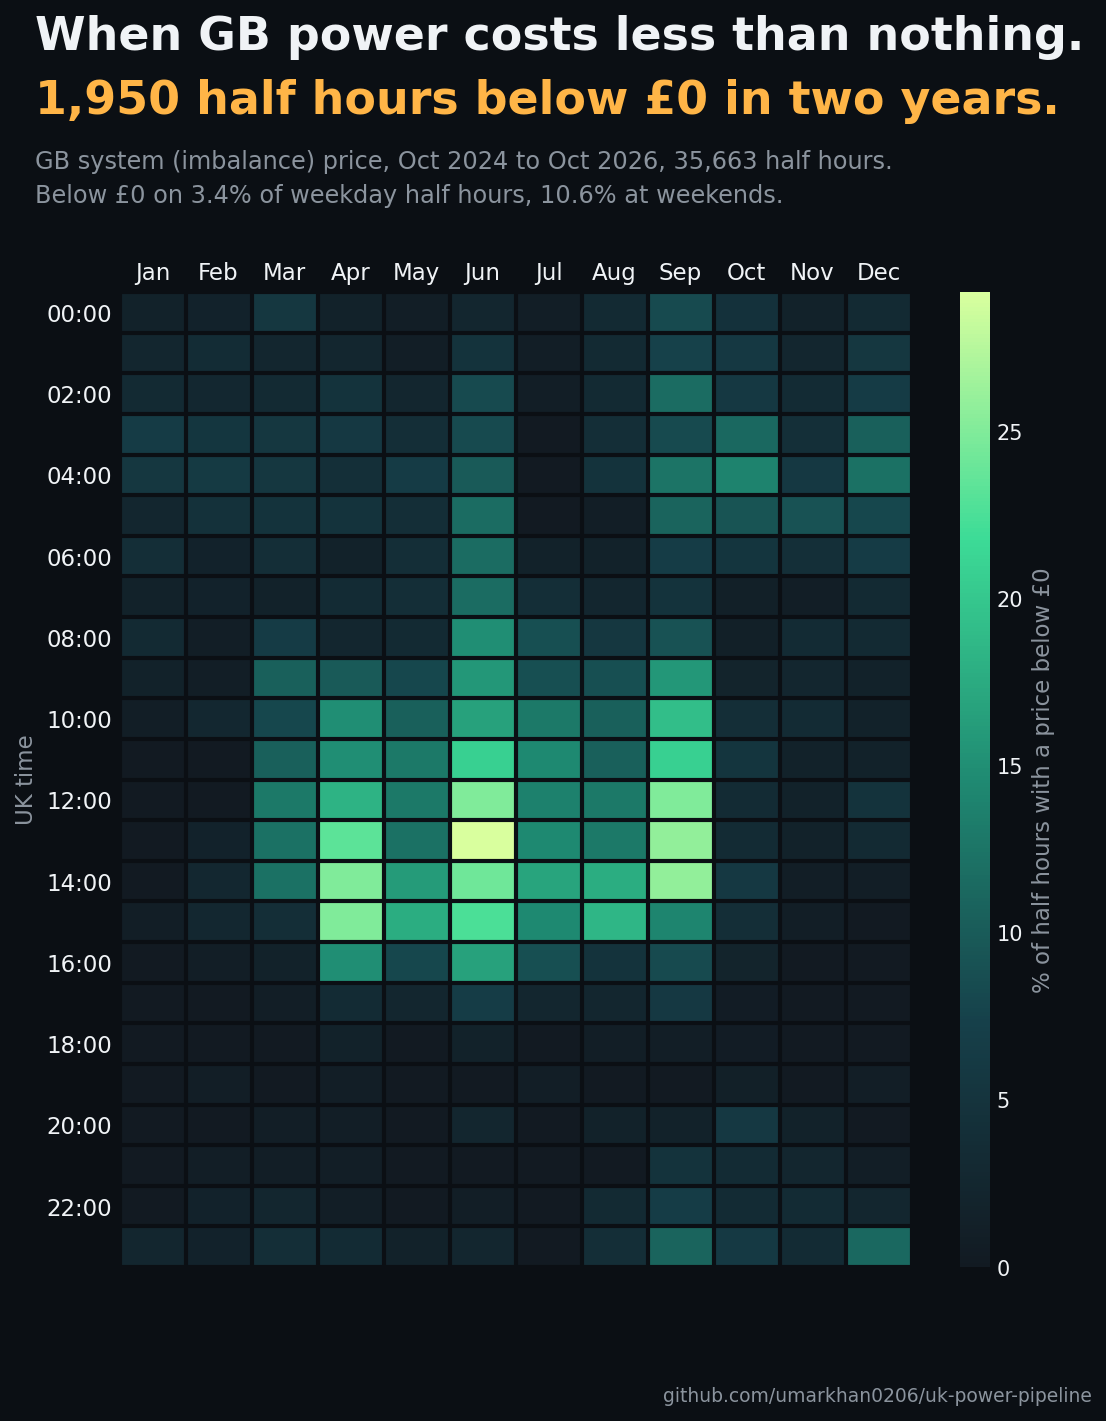

In [0]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pyspark.sql import functions as F

sp = spark.table("workspace.silver.system_prices")
local = F.from_utc_timestamp("start_time_utc", "Europe/London")
df = sp.select(
    F.hour(local).alias("hour"),
    F.month(local).alias("month"),
    F.dayofweek(local).isin(1, 7).alias("weekend"),          # Sunday = 1, Saturday = 7
    (F.col("system_sell_price") < 0).cast("int").alias("neg"),
)

# The real numbers, printed so every figure on the image can be checked
total = df.count()
total_neg = df.agg(F.sum("neg")).first()[0]
rates = {r["weekend"]: 100 * r["rate"] for r in
         df.groupBy("weekend").agg(F.avg("neg").alias("rate")).collect()}
weekday_rate, weekend_rate = rates[False], rates[True]
print(f"half hours: {total:,} | below £0: {total_neg:,} | "
      f"weekday {weekday_rate:.1f}% | weekend {weekend_rate:.1f}%")

cells = df.groupBy("hour", "month").agg((100 * F.avg("neg")).alias("pct"),
                                        F.count("*").alias("n")).toPandas()
grid = cells.pivot(index="hour", columns="month", values="pct").reindex(
    index=range(24), columns=range(1, 13))
print("Top 5 cells:")
print(cells.sort_values("pct", ascending=False).head(5).to_string(index=False))

# The image
plt.rcParams["font.family"] = ["DejaVu Sans"]
BG, FG, GREY, AMBER = "#0b0f14", "#f0f3f6", "#8b949e", "#ffb547"
cmap = LinearSegmentedColormap.from_list(
    "neg", ["#121a22", "#16404a", "#1f8a72", "#3ddc97", "#d9ff9e"])
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig = plt.figure(figsize=(8, 10), dpi=150)
fig.patch.set_facecolor(BG)
ax = fig.add_axes([0.13, 0.12, 0.66, 0.65])
ax.set_facecolor(BG)
im = ax.imshow(grid.values, cmap=cmap, vmin=0, vmax=np.nanmax(grid.values), aspect="auto")
ax.set_xticks(np.arange(-0.5, 12, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 24, 1), minor=True)
ax.grid(which="minor", color=BG, linewidth=2)
ax.tick_params(which="minor", length=0)
ax.set_xticks(range(12), months)
ax.set_yticks(range(0, 24, 2), [f"{h:02d}:00" for h in range(0, 24, 2)])
ax.tick_params(colors=FG, labelsize=11, length=0)
ax.xaxis.tick_top()
for s in ax.spines.values():
    s.set_visible(False)
ax.set_ylabel("UK time", color=GREY, fontsize=11)

cax = fig.add_axes([0.83, 0.12, 0.025, 0.65])
cb = fig.colorbar(im, cax=cax)
cb.outline.set_visible(False)
cb.ax.tick_params(colors=FG, labelsize=10, length=0)
cb.set_label("% of half hours with a price below £0", color=GREY, fontsize=11)

fig.text(0.06, 0.955, "When GB power costs less than nothing.", color=FG, fontsize=22,
         fontweight="bold", va="top")
fig.text(0.06, 0.912, f"{total_neg:,} half hours below £0 in two years.", color=AMBER,
         fontsize=22, fontweight="bold", va="top")
fig.text(0.06, 0.865,
         f"GB system (imbalance) price, Oct 2024 to Oct 2026, {total:,} half hours.\n"
         f"Below £0 on {weekday_rate:.1f}% of weekday half hours, {weekend_rate:.1f}% at weekends.",
         color=GREY, fontsize=11.5, va="top", linespacing=1.5)
fig.text(0.94, 0.03, "github.com/umarkhan0206/uk-power-pipeline", color=GREY, fontsize=9,
         ha="right")

fig.savefig("/Volumes/workspace/bronze/landing/linkedin_part4_negative_prices.png", facecolor=BG)
plt.show()

In [0]:
from pyspark.sql import functions as F

local = F.from_utc_timestamp("start_time_utc", "Europe/London")
sp = (spark.table("workspace.silver.system_prices")
      .select("settlement_date", "settlement_period", "system_sell_price",
              F.hour(local).alias("hour"), F.month(local).alias("month")))

wind = (spark.table("workspace.silver.generation_by_fuel").filter("fuel_type = 'WIND'")
        .select("settlement_date", "settlement_period", F.col("generation").alias("wind_mw")))
solar = (spark.table("workspace.silver.wind_solar_actual").filter("psr_type = 'Solar'")
         .select("settlement_date", "settlement_period", F.col("quantity").alias("solar_mw")))
d = (sp.join(wind, ["settlement_date", "settlement_period"], "left")
       .join(solar, ["settlement_date", "settlement_period"], "left")
       .withColumn("neg", F.col("system_sell_price") < 0))

# 1. Price and negative share by hour of day
print("By UK hour:")
display(d.groupBy("hour").agg(
    F.round(F.avg("system_sell_price"), 1).alias("avg_price"),
    F.round(100 * F.avg(F.col("neg").cast("int")), 1).alias("pct_negative"))
    .orderBy("hour"))

# 2. The exact June 13:00 figure
print("June, 13:00 to 14:00:")
display(d.filter("month = 6 AND hour = 13").agg(
    F.count("*").alias("half_hours"),
    F.round(100 * F.avg(F.col("neg").cast("int")), 1).alias("pct_negative")))

# 3. Is midday negative pricing linked to solar, and night negative pricing to wind?
print("Midday (10:00 to 15:59) and night (00:00 to 05:59), negative against not negative:")
display(d.withColumn("band", F.when(F.col("hour").between(10, 15), "midday")
                              .when(F.col("hour").between(0, 5), "night"))
         .filter("band IS NOT NULL")
         .groupBy("band", "neg").agg(
             F.count("*").alias("half_hours"),
             F.round(F.avg("solar_mw"), 0).alias("avg_solar_mw"),
             F.round(F.avg("wind_mw"), 0).alias("avg_wind_mw"))
         .orderBy("band", "neg"))

By UK hour:


hour,avg_price,pct_negative
0,85.4,3.0
1,82.0,3.6
2,78.9,4.7
3,75.8,6.3
4,76.0,7.4
5,82.6,5.9
6,92.7,4.4
7,99.3,3.4
8,95.1,5.2
9,88.6,7.1


June, 13:00 to 14:00:


half_hours,pct_negative
120,29.2


Midday (10:00 to 15:59) and night (00:00 to 05:59), negative against not negative:


band,neg,half_hours,avg_solar_mw,avg_wind_mw
midday,false,7981,5442.0,7629.0
midday,true,935,8438.0,10640.0
night,false,8457,6.0,7741.0
night,true,459,8.0,13392.0


In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

banded = (d.withColumn("band", F.when(F.col("hour").between(10, 15), "midday")
                                .when(F.col("hour").between(0, 5), "night"))
           .filter("band IS NOT NULL"))

# For each half hour, the average for the same band in the same calendar month
w = Window.partitionBy("band", "month")
rel = (banded
       .withColumn("solar_month_avg", F.avg("solar_mw").over(w))
       .withColumn("wind_month_avg", F.avg("wind_mw").over(w))
       .filter("neg"))

display(rel.groupBy("band").agg(
    F.count("*").alias("negative_half_hours"),
    F.round(100 * (F.avg("solar_mw") / F.avg("solar_month_avg") - 1), 0).alias("solar_vs_same_month_pct"),
    F.round(100 * (F.avg("wind_mw") / F.avg("wind_month_avg") - 1), 0).alias("wind_vs_same_month_pct"),
))

band,negative_half_hours,solar_vs_same_month_pct,wind_vs_same_month_pct
midday,935,8.0,53.0
night,459,25.0,58.0
